<h1 align="center" style="color:green">Fraud Detection Project EDA and Preprocessing</h1>

In [45]:
import pandas as pd
import numpy as np

%load_ext autoreload
%autoreload 2

from insurance_fraud_detection.data_prep import load_data, split_data, drop_bad_rows, fit_cleaner, apply_cleaner
from insurance_fraud_detection.config import TARGET, DROP_COLUMNS


The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload


In [44]:
import warnings
warnings.filterwarnings("ignore", category=FutureWarning)
warnings.filterwarnings("ignore", message=".*select_dtypes.*")

 
- **Data loading**
- **Drop unnecessary columns:** 
    - "policy_number"
    - "rep_number"
- **Split Data**

**Note**:
- Fraud rate: 923 / (14497 + 923) = ~5.99%, so roughly 1 in 17 claims is fraudulent.
- I used Stratified split. With only 923 positive cases total, a random 80/20 split could easily land me with too few or unevenly distributed fraud cases in the test set.

In [35]:
df = load_data()
train_df, test_df = split_data(df)
print(f"Train shape: {train_df.shape},\nTest shape: {test_df.shape}")
print(f"Fraud cases in test set: {test_df[TARGET].sum()}\n")
print(f"Value counts in original data: {df[TARGET].value_counts()}")

Train shape: (12336, 31),
Test shape: (3084, 31)
Fraud cases in test set: 185

Value counts in original data: fraud_found_p
0    14497
1      923
Name: count, dtype: int64


In [36]:
df.head(5)

,month,week_of_month,day_of_week,make,accident_area,day_of_week_claimed,month_claimed,week_of_month_claimed,sex,marital_status,...,age_of_vehicle,age_of_policy_holder,police_report_filed,witness_present,agent_type,number_of_suppliments,address_change_claim,number_of_cars,year,base_policy
0,Dec,5,Wednesday,Honda,Urban,Tuesday,Jan,1,Female,Single,...,3 years,26 to 30,No,No,External,none,1 year,3 to 4,1994,Liability
1,Jan,3,Wednesday,Honda,Urban,Monday,Jan,4,Male,Single,...,6 years,31 to 35,Yes,No,External,none,no change,1 vehicle,1994,Collision
2,Oct,5,Friday,Honda,Urban,Thursday,Nov,2,Male,Married,...,7 years,41 to 50,No,No,External,none,no change,1 vehicle,1994,Collision
3,Jun,2,Saturday,Toyota,Rural,Friday,Jul,1,Male,Married,...,more than 7,51 to 65,Yes,No,External,more than 5,no change,1 vehicle,1994,Liability
4,Jan,5,Monday,Honda,Urban,Tuesday,Feb,2,Female,Single,...,5 years,31 to 35,No,No,External,none,no change,1 vehicle,1994,Collision


## Data cleaning & Preprocessing

**There are no null or duplicate values**

**Columns that need changes:**
- `month_claimed`: I found one row with a value of zero, so I removed it.
- `age`: I found 250 rows with an age of 0 and replaced those values with the median age.

**Note:**

Identified unconventional spellings in `make` (**Accura, Nisson, Mecedes, Porche**). Verified that no correctly spelt duplicates exist for these values, so left as-is. No risk of category fragmentation during encoding.

In [37]:
print(f"Null values in Train DataFrame:\n{train_df.isnull().sum()}\n_________________________")
print(f"Duplicate rows in Train DataFrame: {train_df.duplicated().sum()}")

Null values in Train DataFrame:
month                    0
week_of_month            0
day_of_week              0
make                     0
accident_area            0
day_of_week_claimed      0
month_claimed            0
week_of_month_claimed    0
sex                      0
marital_status           0
age                      0
fault                    0
policy_type              0
vehicle_category         0
vehicle_price            0
fraud_found_p            0
deductible               0
driver_rating            0
days_policy_accident     0
days_policy_claim        0
past_number_of_claims    0
age_of_vehicle           0
age_of_policy_holder     0
police_report_filed      0
witness_present          0
agent_type               0
number_of_suppliments    0
address_change_claim     0
number_of_cars           0
year                     0
base_policy              0
dtype: int64
_________________________
Duplicate rows in Train DataFrame: 0


In [38]:
for name, df in [("Train", train_df), ("Test", test_df)]:
    print(name, (df["month_claimed"] == "0").sum(), (df["day_of_week_claimed"] == "0").sum())

Train 1 1
Test 0 0


In [39]:
train_df = drop_bad_rows(train_df)
print(train_df.shape)         
print((train_df["month_claimed"] == "0").sum()) 

(12335, 31)
0


In [40]:
params = fit_cleaner(train_df)
train_df = apply_cleaner(train_df, params)
test_df = apply_cleaner(test_df, params)

print(params)

{'age': 39.0}


In [41]:
print("Unique values in Train DataFrame:\n")
for col in train_df.select_dtypes(include="object"):
    print(f"{col}: {sorted(train_df[col].unique())}")

Unique values in Train DataFrame:

month: ['Apr', 'Aug', 'Dec', 'Feb', 'Jan', 'Jul', 'Jun', 'Mar', 'May', 'Nov', 'Oct', 'Sep']
day_of_week: ['Friday', 'Monday', 'Saturday', 'Sunday', 'Thursday', 'Tuesday', 'Wednesday']
make: ['Accura', 'BMW', 'Chevrolet', 'Dodge', 'Ferrari', 'Ford', 'Honda', 'Jaguar', 'Lexus', 'Mazda', 'Mecedes', 'Mercury', 'Nisson', 'Pontiac', 'Porche', 'Saab', 'Saturn', 'Toyota', 'VW']
accident_area: ['Rural', 'Urban']
day_of_week_claimed: ['Friday', 'Monday', 'Saturday', 'Sunday', 'Thursday', 'Tuesday', 'Wednesday']
month_claimed: ['Apr', 'Aug', 'Dec', 'Feb', 'Jan', 'Jul', 'Jun', 'Mar', 'May', 'Nov', 'Oct', 'Sep']
sex: ['Female', 'Male']
marital_status: ['Divorced', 'Married', 'Single', 'Widow']
fault: ['Policy Holder', 'Third Party']
policy_type: ['Sedan - All Perils', 'Sedan - Collision', 'Sedan - Liability', 'Sport - All Perils', 'Sport - Collision', 'Sport - Liability', 'Utility - All Perils', 'Utility - Collision', 'Utility - Liability']
vehicle_category: ['Sed

In [42]:
print("Unseen values in Train DataFrame:\n")
for col in test_df.select_dtypes(exclude="number"):
    unseen = set(test_df[col].unique()) - set(train_df[col].unique())
    if unseen:
        print(f"Unseen in train, '{col}': {unseen}")
    else:
        print(f"No unseen values in '{col}'") 

Unseen values in Train DataFrame:

No unseen values in 'month'
No unseen values in 'day_of_week'
No unseen values in 'make'
No unseen values in 'accident_area'
No unseen values in 'day_of_week_claimed'
No unseen values in 'month_claimed'
No unseen values in 'sex'
No unseen values in 'marital_status'
No unseen values in 'fault'
No unseen values in 'policy_type'
No unseen values in 'vehicle_category'
No unseen values in 'vehicle_price'
No unseen values in 'days_policy_accident'
No unseen values in 'days_policy_claim'
No unseen values in 'past_number_of_claims'
No unseen values in 'age_of_vehicle'
No unseen values in 'age_of_policy_holder'
No unseen values in 'police_report_filed'
No unseen values in 'witness_present'
No unseen values in 'agent_type'
No unseen values in 'number_of_suppliments'
No unseen values in 'address_change_claim'
No unseen values in 'number_of_cars'
No unseen values in 'base_policy'


## Exploratory data analysis

### Univariate & Bivariate analysis


In [48]:
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.stats import chi2_contingency
from insurance_fraud_detection.config import BIN_ORDERS

sns.set_theme(style="whitegrid")

continuous_cols = ["age"]
discrete_cols = ["deductible", "driver_rating", "year", "week_of_month", "week_of_month_claimed"]
binned_cols = list(BIN_ORDERS)
nominal_cols = [c for c in train_df.columns
                if c not in continuous_cols + discrete_cols + binned_cols + [TARGET]]

print("nominal:", nominal_cols)
print("binned:", binned_cols)

baseline = train_df[TARGET].mean()
print(f"\nTrain fraud rate: {baseline:.2%} ({train_df[TARGET].sum()} of {len(train_df)})")

nominal: ['month', 'day_of_week', 'make', 'accident_area', 'day_of_week_claimed', 'month_claimed', 'sex', 'marital_status', 'fault', 'policy_type', 'vehicle_category', 'police_report_filed', 'witness_present', 'agent_type', 'base_policy']
binned: ['vehicle_price', 'age_of_vehicle', 'age_of_policy_holder', 'past_number_of_claims', 'number_of_suppliments', 'address_change_claim', 'days_policy_accident', 'days_policy_claim', 'number_of_cars']

Train fraud rate: 5.98% (738 of 12335)


In [54]:
def plot_fraud_rate(df, cols, orders=None, ncols=3):
    orders = orders or {}
    nrows = -(-len(cols) // ncols)
    fig, axes = plt.subplots(nrows, ncols, figsize=(6 * ncols, 4 * nrows))
    axes = axes.flatten()

    for ax, col in zip(axes, cols):
        t = df.groupby(col)[TARGET].agg(["mean", "count"])
        t = t.reindex(orders[col]) if col in orders else t.sort_values("mean", ascending=False)

        ax.bar(t.index.astype(str), t["mean"])
        ax.axhline(baseline, color="red", linestyle="--", linewidth=2)
        for i, (rate, n) in enumerate(zip(t["mean"], t["count"])):
            ax.text(i, rate, f"n={n}", ha="center", va="bottom", fontsize=7)
        ax.set_title(col)
        ax.set_ylabel("fraud rate")
        ax.tick_params(axis="x", rotation=45)

    for ax in axes[len(cols):]:
        ax.axis("off")
    plt.tight_layout()
    plt.show()

- Univariate, numeric


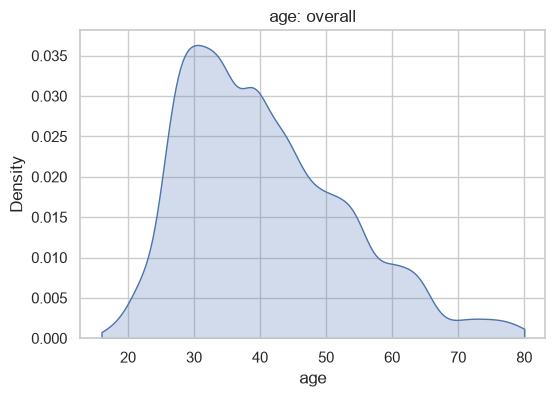

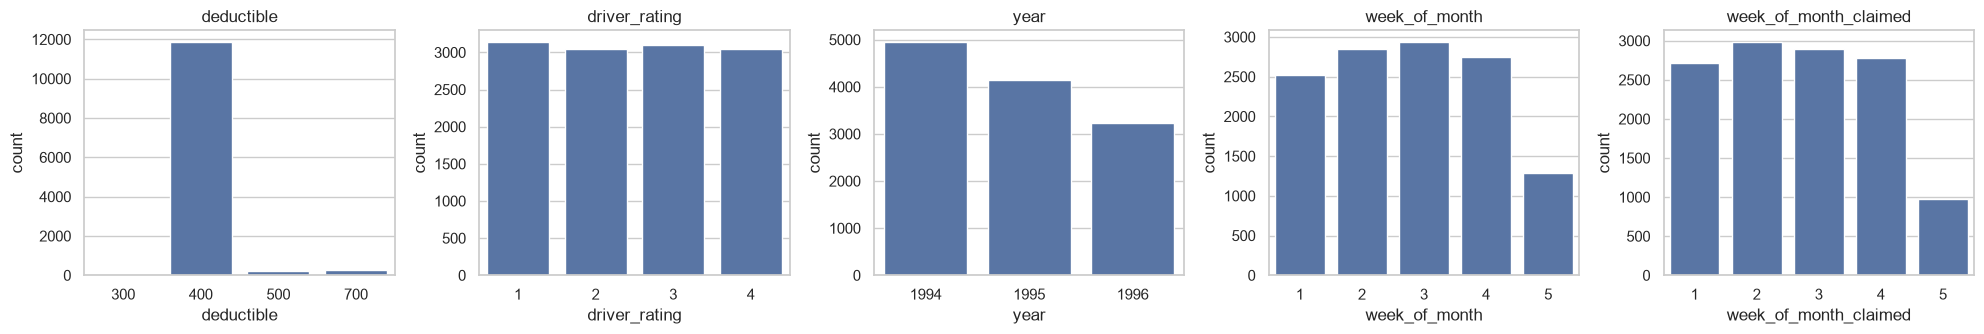

In [55]:
# Continuous: age
fig, ax = plt.subplots(figsize=(6, 4))
sns.kdeplot(data=train_df, x="age", fill=True, cut=0, ax=ax)
ax.set_title("age: overall")
plt.show()

# Discrete: count plots
fig, axes = plt.subplots(1, len(discrete_cols), figsize=(4 * len(discrete_cols), 3.5))
for ax, col in zip(axes, discrete_cols):
    sns.countplot(data=train_df, x=col, order=sorted(train_df[col].unique()), ax=ax)
    ax.set_title(col)
plt.tight_layout()
plt.show()

- Bivariate, nominal columns vs target


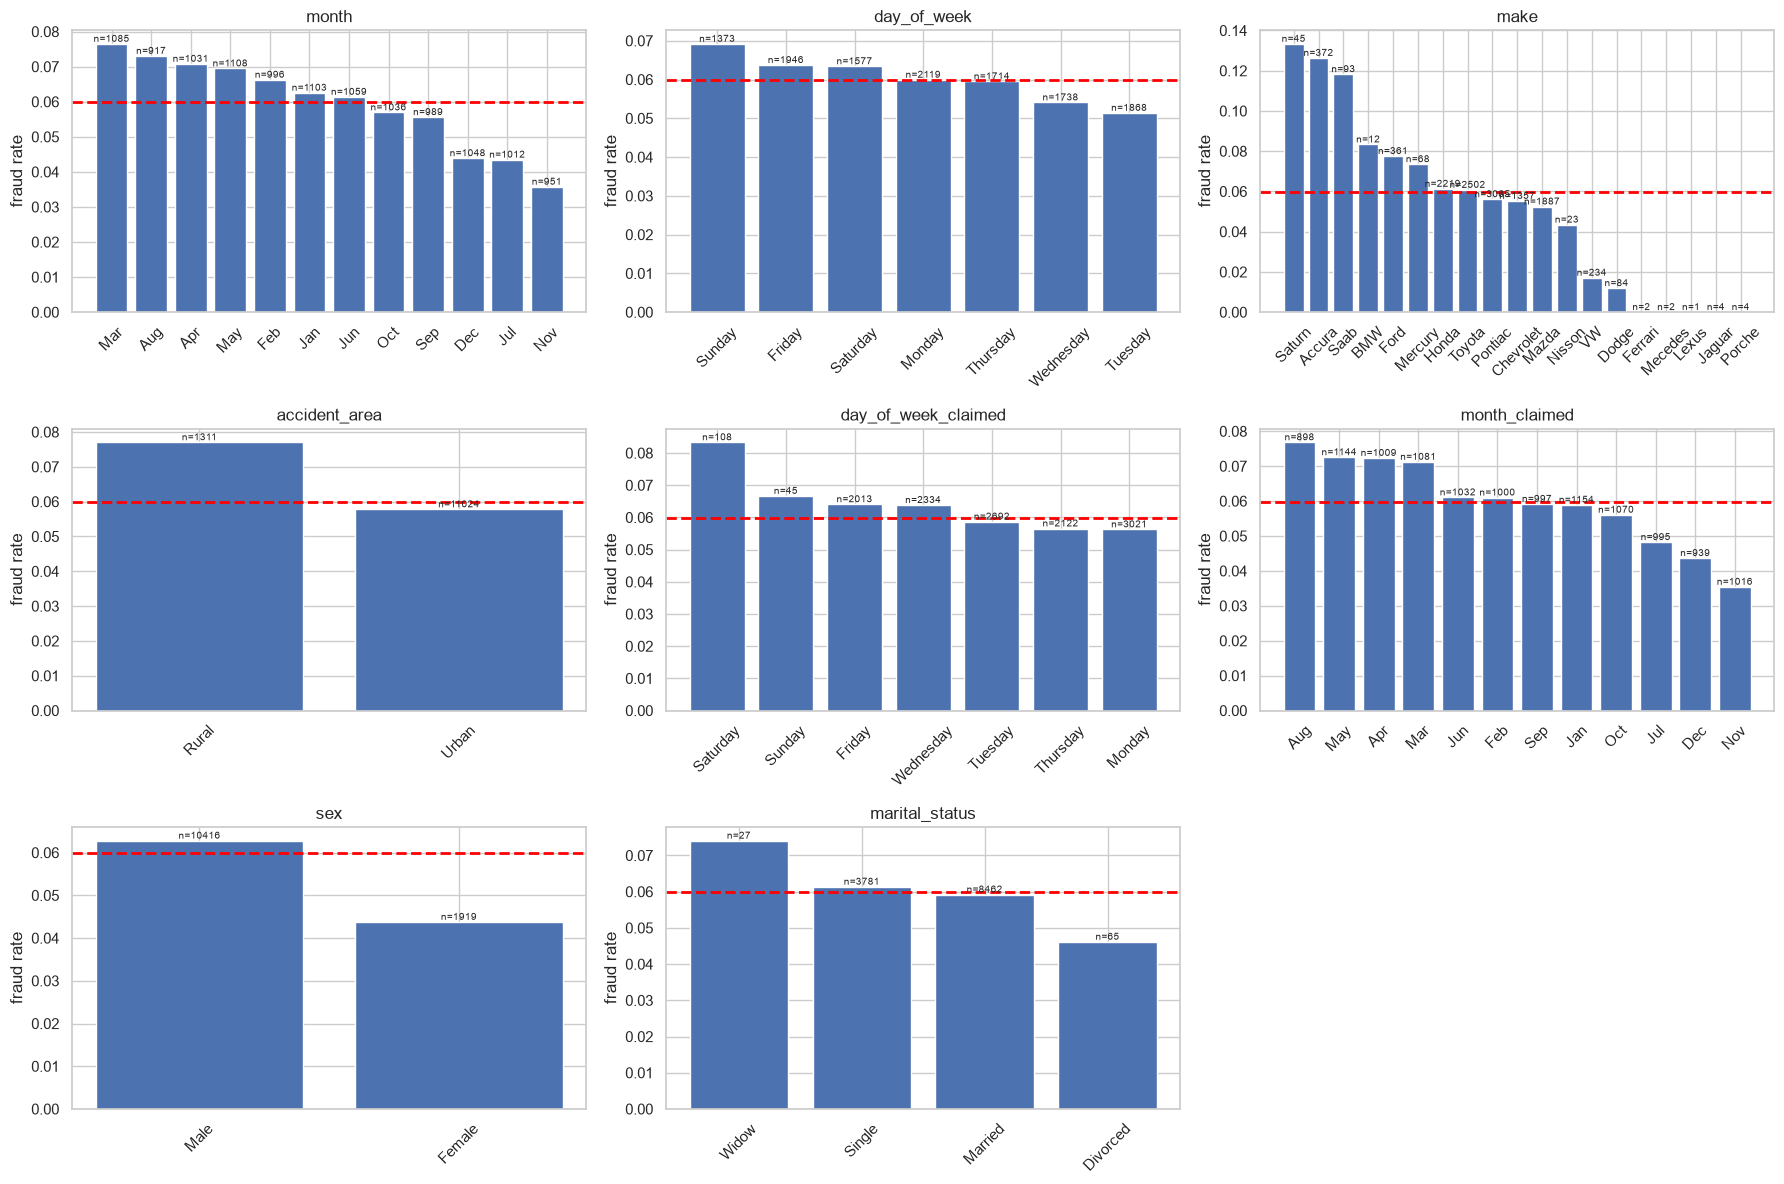

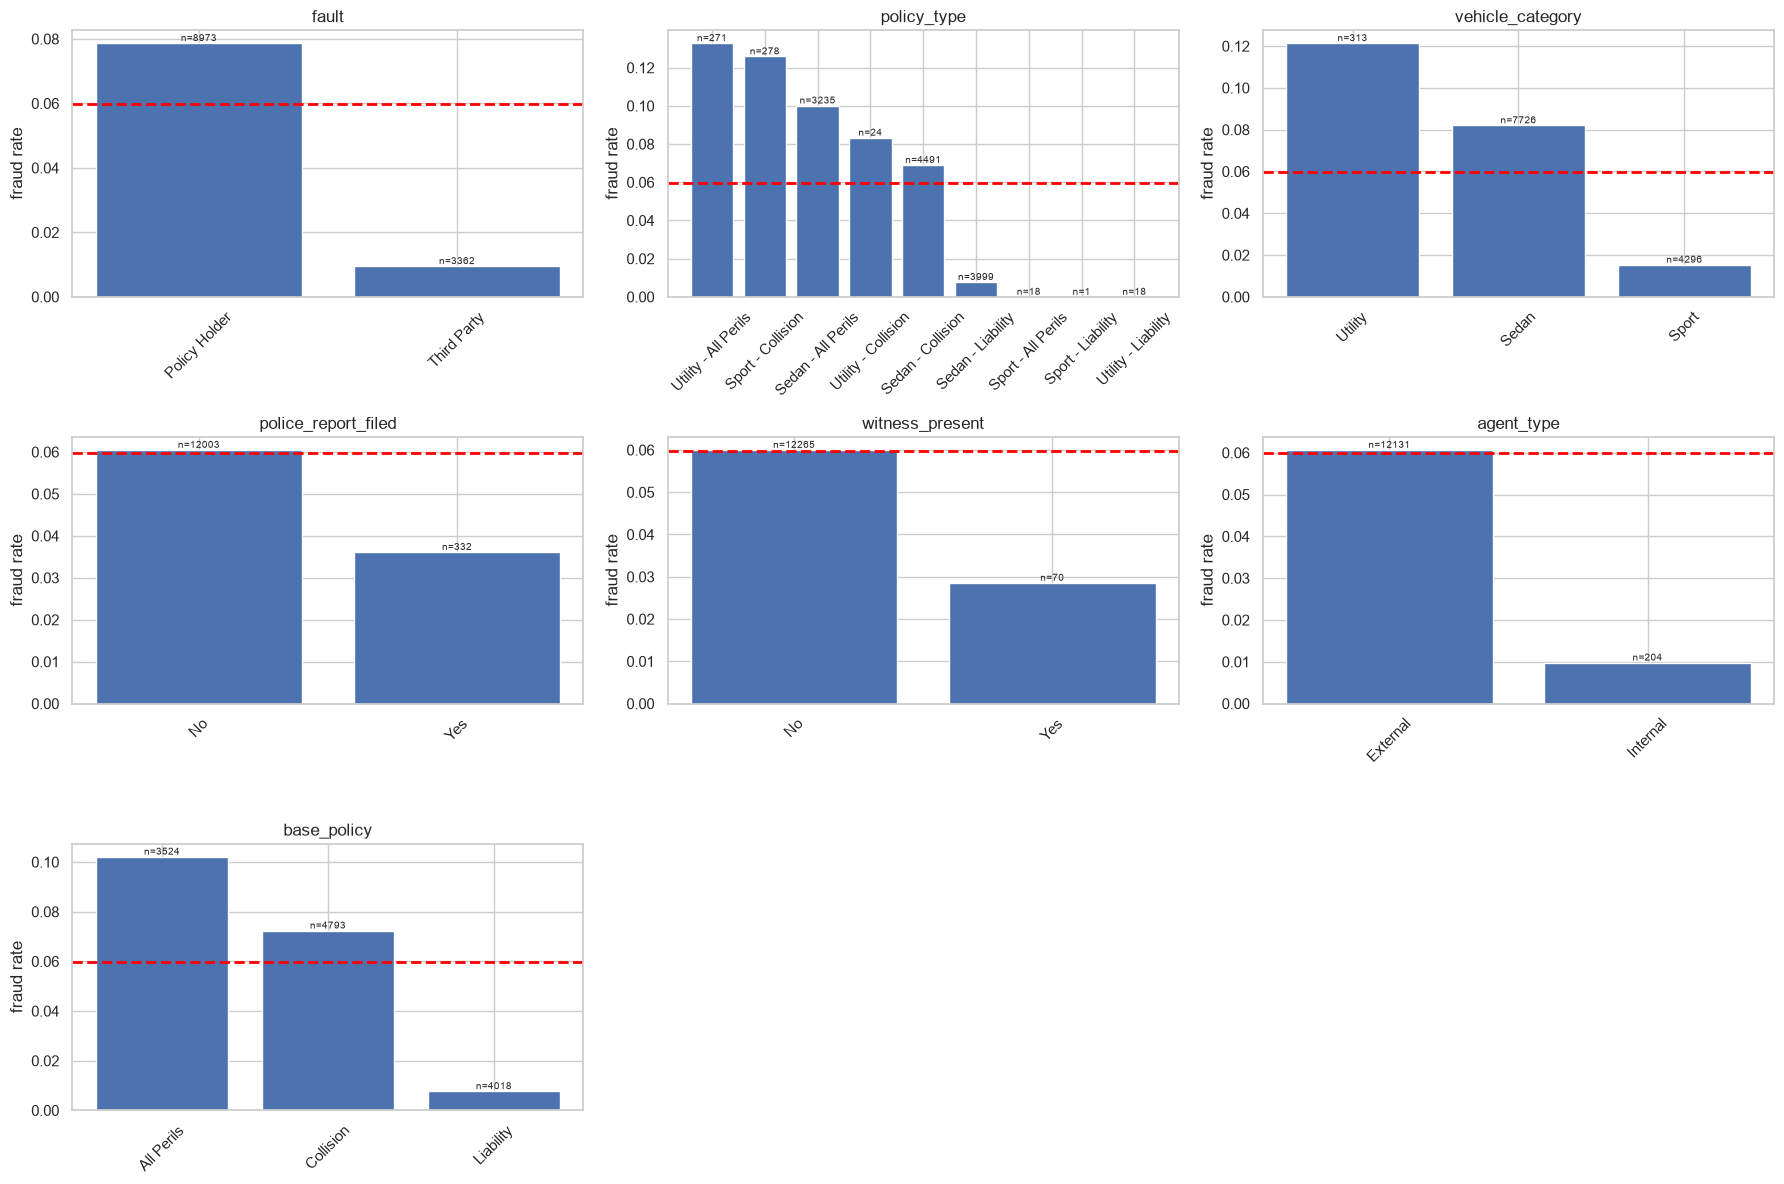

In [56]:
half = len(nominal_cols) // 2 + len(nominal_cols) % 2
plot_fraud_rate(train_df, nominal_cols[:half])
plot_fraud_rate(train_df, nominal_cols[half:])

-  bivariate, binned columns vs target (natural order from BIN_ORDERS)

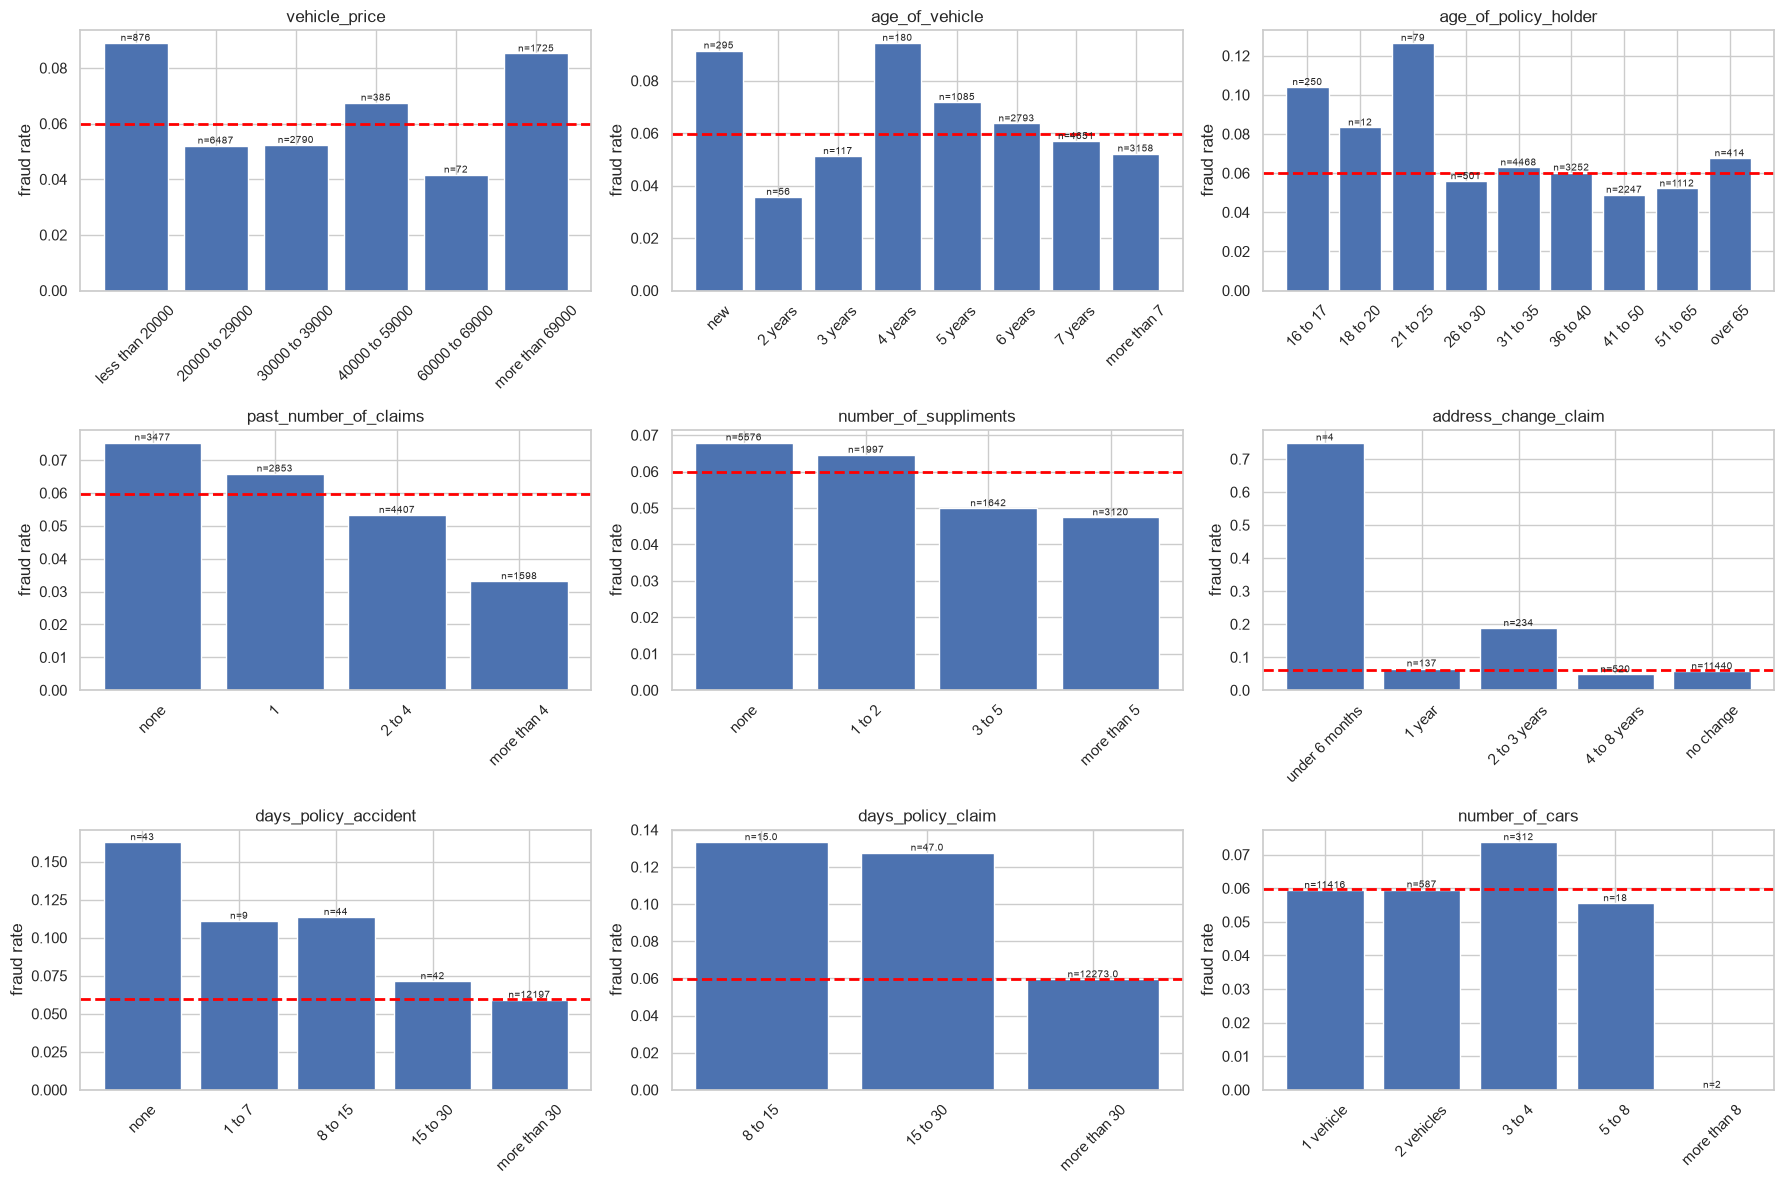

In [58]:
plot_fraud_rate(train_df, binned_cols, orders=BIN_ORDERS)

- Bivariate, numeric vs target


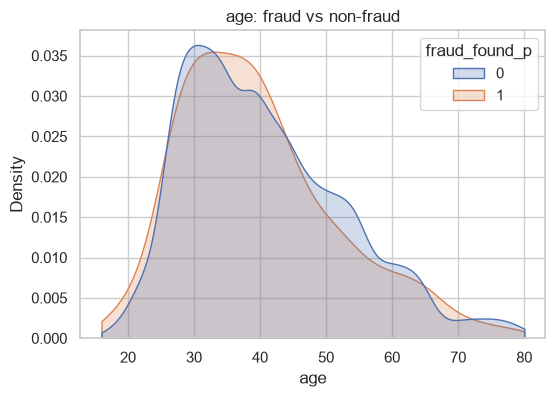

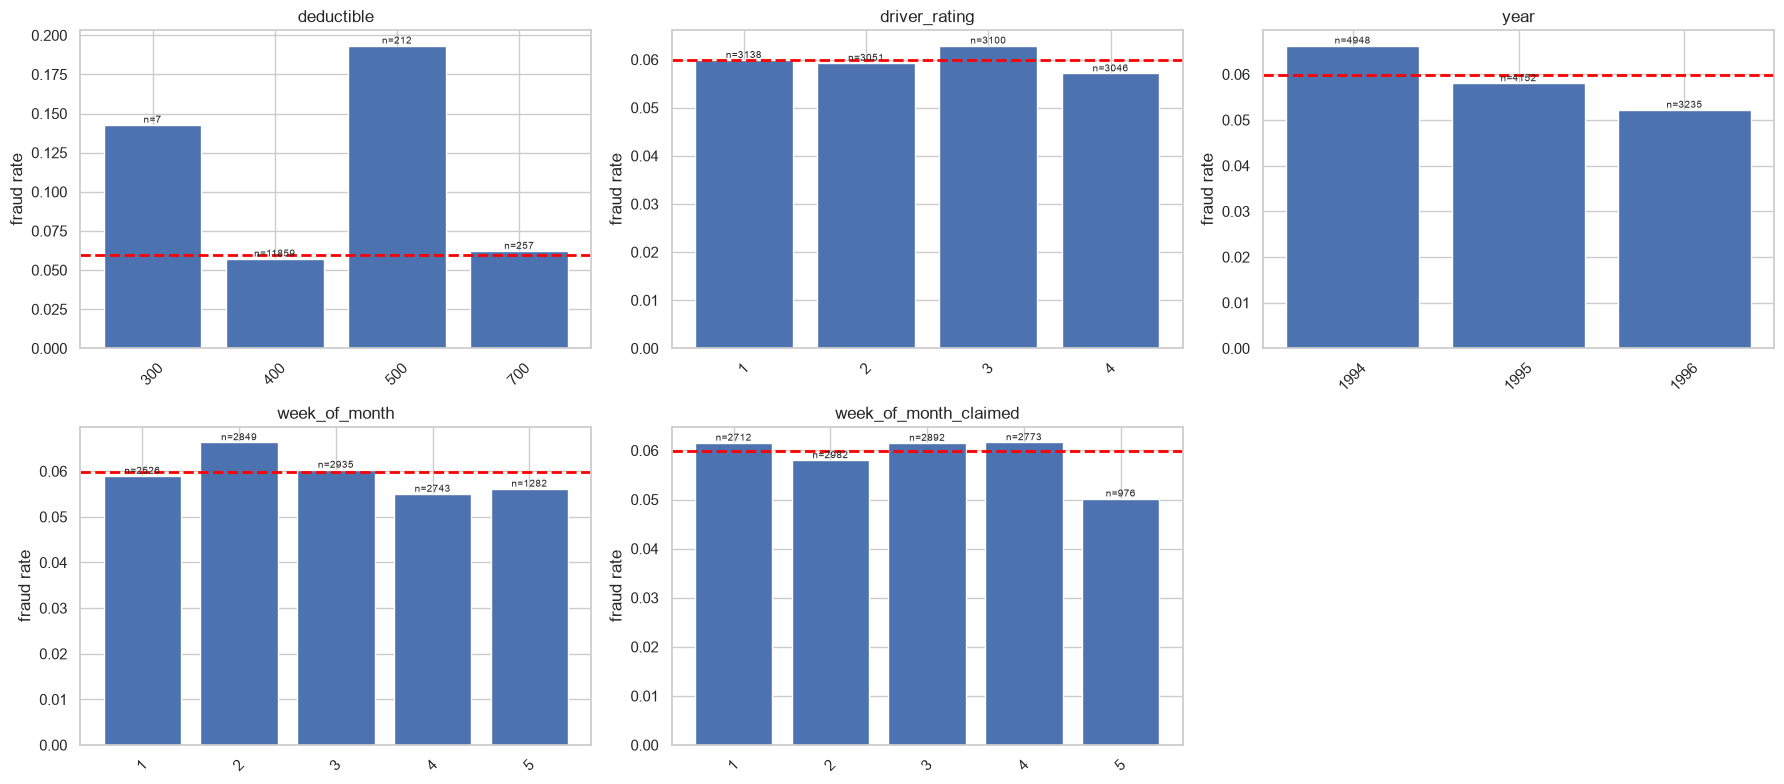

In [57]:
# Continuous: age, fraud vs non-fraud
fig, ax = plt.subplots(figsize=(6, 4))
sns.kdeplot(data=train_df, x="age", hue=TARGET, common_norm=False,
            fill=True, cut=0, ax=ax)
ax.set_title("age: fraud vs non-fraud")
plt.show()

# Discrete: fraud rate per value, with n
discrete_orders = {c: sorted(train_df[c].unique()) for c in discrete_cols}
plot_fraud_rate(train_df, discrete_cols, orders=discrete_orders)

## EDA summary

**Baseline fraud rate:** ~6%. Rates are judged against this, and only trusted when the sample size is large.

### Strong signal
- **fault:** Policy Holder ~8% vs Third Party ~1%
- **base_policy / policy_type:** All Perils ~10%, Collision ~7%, Liability ~0.8%
- **past_number_of_claims:** falls from 7.5% (none) to 3.3% (more than 4)

### Weaker signal
- **vehicle_category:** Utility ~12%, Sedan ~8%, Sport ~1.5% (overlaps heavily with base_policy)
- **address_change_claim:** "2 to 3 years" ~19% (n=234)
- **deductible:** 500 ~19% (n=212)
- **agent_type:** Internal ~1% vs External ~6%
- **number_of_suppliments:** mild decline, 6.8% to 4.7%
- **vehicle_price:** weak U-shape, both ends ~9%
- **age_of_policy_holder:** only the under-25 bins run high
- **age_of_vehicle, month, make (Accura), sex, accident_area, year:** small gaps

### No signal
age, driver_rating, week_of_month, week_of_month_claimed, day_of_week, number_of_cars

### Carry forward to IV / WOE
All columns from the strong and weaker lists. The signal is not monotone in vehicle_price,
address_change_claim and age_of_policy_holder, so use WOE on bins for those, after merging sparse bins.